# 03 · Audio: voice verification (Member 3)

This notebook turns each member's voice recordings into a model that can confirm
a transaction. It produces:

| Output | Used by |
|---|---|
| `data/audio_features.csv` | assignment deliverable |
| `models/voice_model.pkl` | `scripts/voice_model.py` → `verify_voice()` in the app |
| `report/figures/audio_*.png` | report, voice section |

**Before running:** put the recordings in `data/audio/<firstname>/` named
`yes_approve.wav` and `confirm_transaction.wav` (extra takes: `yes_approve_2.wav`, …),
and the non-member's clip(s) in `data/unauthorized/`. Then choose **Run All**.

Feature extraction lives in `scripts/voice_model.py`, so the app processes a new
clip in exactly the same way as the training clips.

In [1]:
import subprocess
import sys
import warnings
from pathlib import Path

import joblib
import librosa
import librosa.display
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Audio, display
from sklearn.base import clone
from sklearn.decomposition import PCA
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (ConfusionMatrixDisplay, accuracy_score, f1_score,
                             log_loss)
from sklearn.model_selection import LeaveOneGroupOut
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", message=".*n_fft.*too large.*")
warnings.filterwarnings("ignore", message=".*PySoundFile failed.*")
warnings.filterwarnings("ignore", message=".*audioread.*")

# Find the project root: the folder that contains scripts/voice_model.py
ROOT = Path.cwd().resolve()
while not (ROOT / "scripts" / "voice_model.py").exists():
    if ROOT.parent == ROOT:
        raise FileNotFoundError("Open this notebook from inside the project folder.")
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / "scripts"))
import voice_model as vm

AUDIO_DIR = ROOT / "data" / "audio"
UNAUTHORIZED_DIR = ROOT / "data" / "unauthorized"
FEATURES_CSV = ROOT / "data" / "audio_features.csv"
MODEL_PATH = ROOT / "models" / "voice_model.pkl"
FIG_DIR = ROOT / "report" / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)
MODEL_PATH.parent.mkdir(parents=True, exist_ok=True)

SR = vm.SAMPLE_RATE
SEED = 42
rng = np.random.default_rng(SEED)
plt.rcParams.update({"figure.dpi": 100, "savefig.dpi": 150, "savefig.bbox": "tight"})

def rel(path):
    """Path relative to the project root, for tidy printing."""
    return Path(path).resolve().relative_to(ROOT).as_posix()

print("Project root:", ROOT)

Project root: D:\ALU_Trials\dataPreProcessing


## 1. Load and check the recordings

Every file is checked before it is used. A file is flagged if:

| Check | Rule | Fix |
|---|---|---|
| Too short | less than 0.5 s of speech | re-record, say the full phrase |
| Too long | file longer than 10 s | trim the silence |
| Too quiet | speech below −40 dBFS | record closer to the microphone |
| Clipping | more than 0.1 % of samples at full scale | record further away or lower the input gain |
| Unexpected name | not `yes_approve` / `confirm_transaction` (+ optional `_2`, `_3`) | rename the file |
| Unreadable | the file can't be decoded | export as `.wav` |

In [2]:
MIN_SPEECH_SECONDS = 0.5
MAX_FILE_SECONDS = 10.0
QUIET_DBFS = -40.0
CLIP_LEVEL, MAX_CLIPPED = 0.99, 0.001

def check_recording(path, check_name=True):
    """Measure one file at its original sample rate and list any problems."""
    info = {"file": rel(path)}
    try:
        y, sr = librosa.load(path, sr=None, mono=True)
    except Exception as exc:
        return {**info, "issues": f"unreadable ({type(exc).__name__})"}
    speech, _ = librosa.effects.trim(y, top_db=vm.TRIM_TOP_DB)
    speech_rms = np.sqrt(np.mean(speech ** 2)) if speech.size else 0.0
    info.update(
        sample_rate=sr,
        duration_s=round(len(y) / sr, 2),
        speech_s=round(len(speech) / sr, 2),
        loudness_dbfs=round(20 * np.log10(speech_rms + 1e-12), 1),
        clipped_pct=round(100 * np.mean(np.abs(y) >= CLIP_LEVEL), 3),
    )
    issues = []
    if info["speech_s"] < MIN_SPEECH_SECONDS:
        issues.append("too short")
    if info["duration_s"] > MAX_FILE_SECONDS:
        issues.append("too long")
    if info["loudness_dbfs"] < QUIET_DBFS:
        issues.append("too quiet")
    if info["clipped_pct"] > 100 * MAX_CLIPPED:
        issues.append("clipping")
    if check_name and vm.parse_recording_name(path)[0] not in vm.PHRASES:
        issues.append("unexpected name")
    info["issues"] = ", ".join(issues)
    return info

recordings = pd.DataFrame(vm.find_recordings(AUDIO_DIR))
if recordings.empty:
    raise FileNotFoundError(
        f"No recordings in {rel(AUDIO_DIR)}. Add data/audio/<firstname>/yes_approve.wav etc."
    )
unauthorized = pd.DataFrame(vm.find_recordings(UNAUTHORIZED_DIR))

quality = pd.DataFrame(
    [{"member": r.member, **check_recording(r.path)} for r in recordings.itertuples()]
    + [{"member": "(unauthorized)", **check_recording(r.path, check_name=False)}
       for r in unauthorized.itertuples()]
)
display(quality)

flagged = quality[quality["issues"] != ""]
if flagged.empty:
    print("All recordings passed the checks.")
else:
    print("Re-record or fix these files:")
    for row in flagged.itertuples():
        print(f"  - {row.file}: {row.issues}")

D:\ALU_Trials\dataPreProcessing\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


,member,file,sample_rate,duration_s,speech_s,loudness_dbfs,clipped_pct,issues
0,amazing,data/audio/amazing/confirm_transaction.wav,48000,1.71,1.40,-23.799999,0.0,
1,amazing,data/audio/amazing/yes_approve.wav,48000,1.71,1.19,-24.500000,0.0,
2,gilbert,data/audio/gilbert/confirm_transaction.wav,48000,5.53,4.68,-24.500000,0.0,
3,gilbert,data/audio/gilbert/yes_approve.wav,48000,4.29,3.19,-22.100000,0.0,
4,kate,data/audio/kate/confirm_transaction.wav,48000,3.58,2.82,-33.799999,0.0,
5,kate,data/audio/kate/yes_approve.wav,48000,3.14,2.15,-31.400000,0.0,
6,(unauthorized),data/unauthorized/Frank_Confirm_transaction.wav,48000,2.45,1.85,-26.400000,0.0,
7,(unauthorized),data/unauthorized/Frank_Yes_approve.wav,48000,2.19,0.85,-21.600000,0.0,
8,(unauthorized),data/unauthorized/gabriella_confirm_01.wav,44100,3.11,2.87,-41.700001,0.0,too quiet
9,(unauthorized),data/unauthorized/gabriella_yesapprove_01.wav,44100,2.87,2.39,-39.400002,0.0,


Re-record or fix these files:
  - data/unauthorized/gabriella_confirm_01.wav: too quiet


In [3]:
# Drop files that can't be read, then check that every member said both phrases.
unreadable = set(quality.loc[quality["issues"].str.startswith("unreadable"), "file"])
recordings = recordings[~recordings["path"].map(rel).isin(unreadable)].reset_index(drop=True)
unauthorized = (unauthorized[~unauthorized["path"].map(rel).isin(unreadable)].reset_index(drop=True)
                if not unauthorized.empty else unauthorized)
recordings["recording_id"] = recordings["member"] + "/" + recordings["path"].map(lambda p: p.name)

coverage = (recordings.groupby(["member", "phrase"]).size()
            .unstack(fill_value=0)
            .reindex(columns=list(vm.PHRASES), fill_value=0))
display(coverage)

MEMBERS = sorted(recordings["member"].unique())
for member in MEMBERS:
    missing = [p for p in vm.PHRASES if coverage.loc[member, p] == 0]
    if missing:
        print(f"WARNING: {member} has no recording of: {', '.join(missing)}")
    if (recordings["member"] == member).sum() < 2:
        print(f"WARNING: {member} has only one recording, so it can't be tested on an unseen clip.")
if len(MEMBERS) < 2:
    raise ValueError("The voice model needs recordings from at least two members.")
if unauthorized.empty:
    print("WARNING: no clip in data/unauthorized/, so the approval threshold can't be tuned.")
ONE_TAKE = bool((coverage.reindex(columns=list(vm.PHRASES)) <= 1).all().all())
if ONE_TAKE:
    print("NOTE: everyone has one take per phrase. Section 6 will then test whether the model\n"
          "      recognises a voice saying the *other* phrase, which is harder than the app's job.\n"
          "      A second take of each phrase (yes_approve_2.wav, ...) gives a fairer test.")

print(f"\n{len(recordings)} recordings from {len(MEMBERS)} members: {', '.join(MEMBERS)}")
print(f"{len(unauthorized)} unauthorized clip(s)")
# Fixed person-level split before fitting: Placide is never used to tune the threshold.
CALIBRATION_PEOPLE = {'frank', 'gabriella'}
TEST_PEOPLE = {'placide'}
unauthorized['person'] = unauthorized['path'].map(lambda p: p.stem.split('_')[0].lower())
assert set(unauthorized['person']) == CALIBRATION_PEOPLE | TEST_PEOPLE
unauthorized['split'] = unauthorized['person'].map(lambda name: 'test' if name in TEST_PEOPLE else 'calibration')
display(unauthorized[['person', 'split', 'path']])


phrase,yes_approve,confirm_transaction
member,,
amazing,1,1
gilbert,1,1
kate,1,1


NOTE: everyone has one take per phrase. Section 6 will then test whether the model
      recognises a voice saying the *other* phrase, which is harder than the app's job.
      A second take of each phrase (yes_approve_2.wav, ...) gives a fairer test.

6 recordings from 3 members: amazing, gilbert, kate
6 unauthorized clip(s)


,person,split,path
0,frank,calibration,D:\ALU_Trials\dataPreProcessing\data\unauthori...
1,frank,calibration,D:\ALU_Trials\dataPreProcessing\data\unauthori...
2,gabriella,calibration,D:\ALU_Trials\dataPreProcessing\data\unauthori...
3,gabriella,calibration,D:\ALU_Trials\dataPreProcessing\data\unauthori...
4,placide,test,D:\ALU_Trials\dataPreProcessing\data\unauthori...
5,placide,test,D:\ALU_Trials\dataPreProcessing\data\unauthori...


## 2. Waveforms and spectrograms

Each clip is resampled to 16 kHz, trimmed of leading and trailing silence and
peak-normalised (the same processing the app applies), then plotted. The
**waveform** shows loudness over time; the **mel spectrogram** shows which
frequencies carry energy over time (brighter = louder).

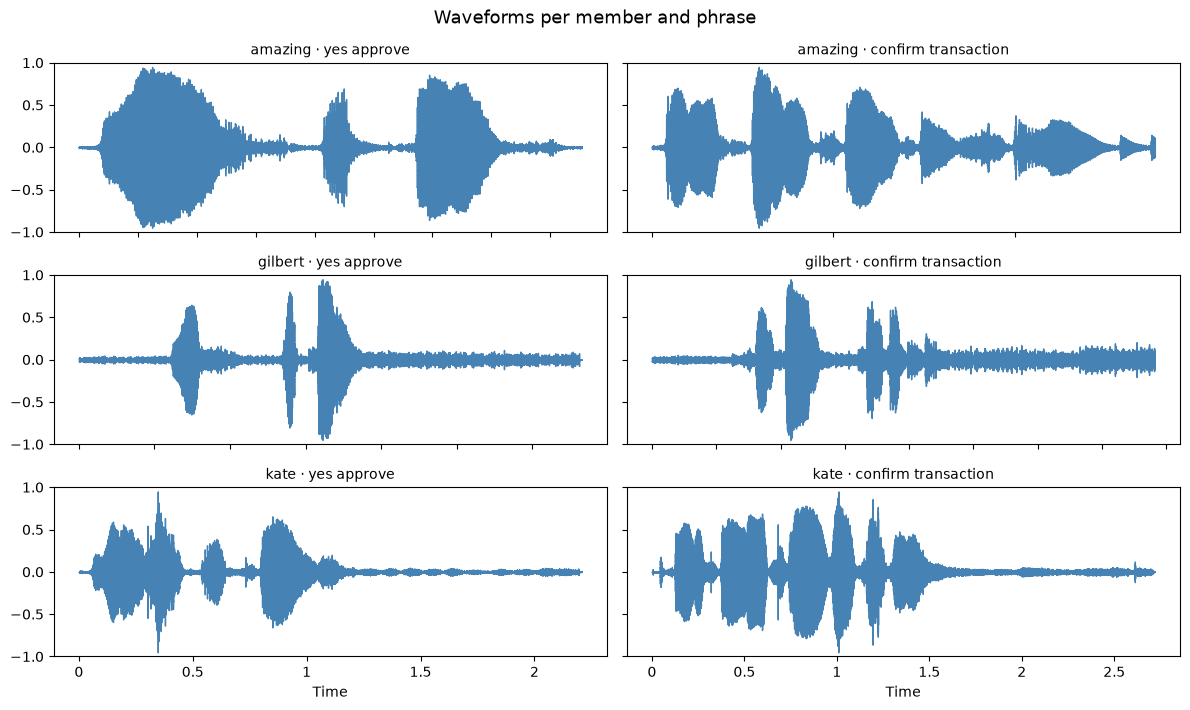

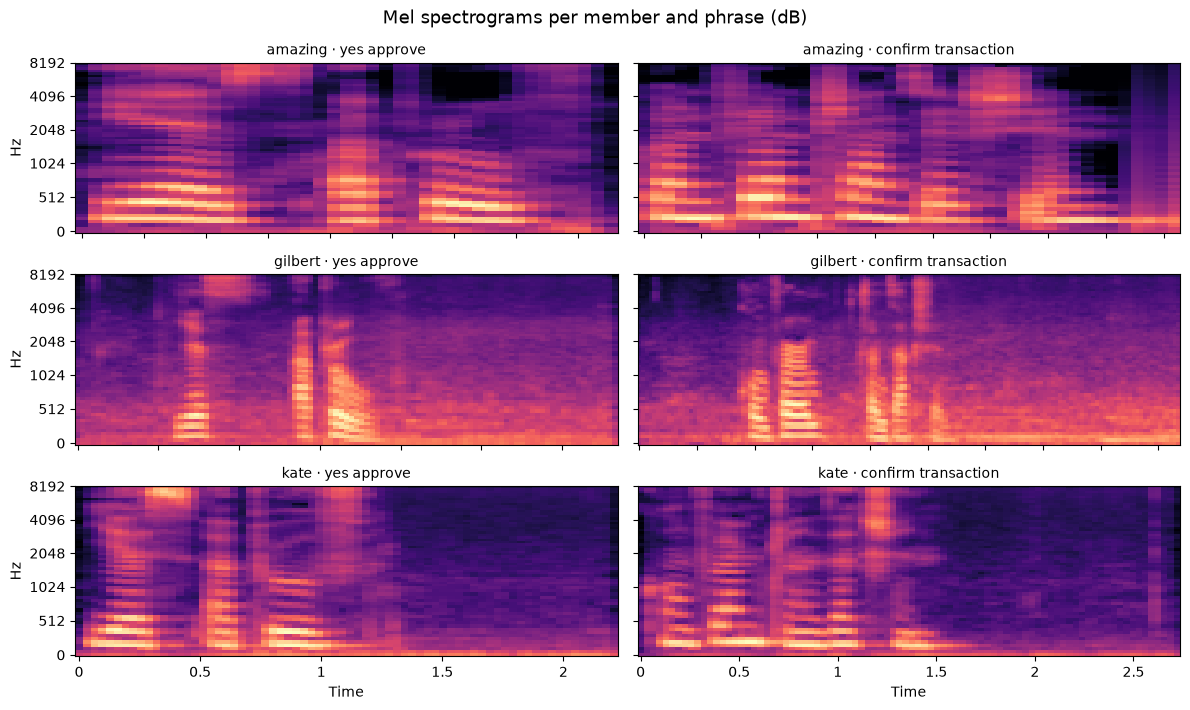

In [4]:
clips = {r.recording_id: vm.load_audio(r.path) for r in recordings.itertuples()}
unauthorized_clips = {f"unauthorized/{r.path.name}": vm.load_audio(r.path)
                      for r in unauthorized.itertuples()}

# First take of each phrase for each member
examples = (recordings.sort_values("take")
            .drop_duplicates(["member", "phrase"])
            .set_index(["member", "phrase"])["recording_id"])
found = set(recordings["phrase"])
phrases = [p for p in vm.PHRASES if p in found] + sorted(found - set(vm.PHRASES))

def example_grid(plot_fn, title, filename):
    fig, axes = plt.subplots(len(MEMBERS), len(phrases),
                             figsize=(6 * len(phrases), 2.4 * len(MEMBERS)),
                             squeeze=False, sharey="row")
    for i, member in enumerate(MEMBERS):
        for j, phrase in enumerate(phrases):
            ax = axes[i, j]
            rid = examples.get((member, phrase))
            if rid is None:
                ax.text(0.5, 0.5, "missing", ha="center", va="center", transform=ax.transAxes)
                ax.set_axis_off()
                continue
            plot_fn(clips[rid], ax)
            ax.set_title(f"{member} · {phrase.replace('_', ' ')}", fontsize=10)
            ax.label_outer()
    fig.suptitle(title, fontsize=13)
    fig.tight_layout()
    fig.savefig(FIG_DIR / filename)
    plt.show()

def plot_wave(y, ax):
    librosa.display.waveshow(y, sr=SR, ax=ax, color="steelblue")
    ax.set_ylim(-1, 1)

def plot_mel(y, ax):
    mel = librosa.power_to_db(librosa.feature.melspectrogram(y=y, sr=SR, n_mels=64), ref=np.max)
    librosa.display.specshow(mel, sr=SR, x_axis="time", y_axis="mel", ax=ax, cmap="magma")

example_grid(plot_wave, "Waveforms per member and phrase", "audio_waveforms.png")
example_grid(plot_mel, "Mel spectrograms per member and phrase (dB)", "audio_spectrograms.png")

In [5]:
# Listen to each example
for (member, phrase), rid in examples.items():
    print(f"{member} · {phrase}")
    display(Audio(clips[rid], rate=SR))
for name, y in unauthorized_clips.items():
    print(name)
    display(Audio(y, rate=SR))

amazing · confirm_transaction


amazing · yes_approve


gilbert · confirm_transaction


gilbert · yes_approve


kate · confirm_transaction


kate · yes_approve


... (2 outputs left out)

unauthorized/gabriella_confirm_01.wav


unauthorized/gabriella_yesapprove_01.wav


unauthorized/Placide_Confirm_transaction.wav


unauthorized/Placide_Yes_approve.wav


## 3. What the plots show

The following interpretation is based on the waveform and mel-spectrogram plots
and the recording-quality measurements above. It describes the current six
member recordings; it does not assume that these patterns hold for every future
take by the same speaker.

**Waveforms and timing.** Amazing's two original files are both 1.71 seconds long,
compared with 4.29 and 5.53 seconds for Gilbert and 3.14 and 3.58 seconds for Kate
(yes approve and confirm transaction, respectively). After the quality check's
silence trimming, the retained lengths are 1.19/1.40 seconds for Amazing,
3.19/4.68 seconds for Gilbert, and 2.15/2.82 seconds for Kate. These are retained
signal lengths, not precise measurements of voiced speech: low-level background
sound can remain after trimming. The waveforms show separate bursts of energy
and pauses. The confirm-transaction examples have more bursts and last longer
than the yes-approve examples. Gilbert's plots retain a visible low-amplitude
background before and after the main speech, while Kate's main speech is
followed by a quieter tail. Amazing's speech occupies more of the retained clip.

**Loudness and quality.** The plots are peak-normalised, so similar peak heights
do not mean that the recordings originally had equal loudness. The original
quality measurements place Amazing at about -24.5 to -23.8 dBFS, Gilbert at
-24.5 to -22.1 dBFS, and Kate at -33.8 to -31.4 dBFS. Kate's recordings are
therefore quieter, although all six member recordings pass the configured
checks. No samples exceed the clipping threshold in the reported measurements.
Gabriella's unauthorized confirm recording is flagged too quiet at -41.7 dBFS;
her yes-approve recording is -39.4 dBFS, close to the -40 dBFS cutoff. These
readable recordings remain in the analysis. Normalising them increases both
speech and background sound, so a clearer replacement recording would be useful.

**Spectrograms.** All three speakers show bright low-frequency bands during
voiced portions, with intermittent energy at higher frequencies. Amazing and
Kate both show visible harmonic bands separated by darker pauses. Gilbert's
plots show more persistent low-frequency energy and a diffuse background
between speech bursts, consistent with the residual signal in his waveforms.
Differences in the band patterns and their timing motivate the use of MFCCs,
pitch, spectral roll-off and energy features. However, these mel plots alone
do not establish which pair of speakers is most similar or prove a pitch ranking.
Brightness is relative to each clip's maximum, so it cannot be used to compare
absolute recording loudness across panels.

**Implications for recognition.** The recordings contain useful differences in
spectral shape and speech timing, but the model may also learn microphone or
room differences. In particular, Gilbert's persistent background could make
his current samples easier to separate without demonstrating robust speaker
recognition. Additional takes in different sessions, with more consistent
recording conditions, are needed to check that the model recognises the speaker
rather than the recording environment. Augmentations add variation but do not
replace independently recorded examples.


## 4. Augmentation

With only a few recordings per person, overfitting is a risk. Each recording
gets five altered copies to expose the model to modest variation; this does not
guarantee that it learns speaker identity rather than recording conditions:

| Augmentation | Setting | Simulates |
|---|---|---|
| `pitch_up` / `pitch_down` | ±1.5 semitones | a slightly higher or lower voice (tired, excited) |
| `stretch_fast` / `stretch_slow` | 1.15× / 0.85× speed | speaking faster or slower |
| `noise` | pink background noise at 20 dB SNR | a room with a fan, traffic or distant chatter |

Pitch shifts are kept small on purpose: a large shift would change who the voice
sounds like. Each copy is peak-normalised again, like a real clip.

In [6]:
def checked(fn, y, **kwargs):
    """Run a librosa effect and check the result is valid audio.

    librosa 1.0's phase vocoder prints a harmless "invalid value encountered in
    cast" warning on some clips; it is silenced here and the output checked instead.
    """
    with warnings.catch_warnings(), np.errstate(invalid="ignore"):
        warnings.filterwarnings("ignore", message="invalid value encountered in cast")
        out = fn(y, **kwargs)
    assert np.isfinite(out).all(), f"{fn.__name__} produced invalid samples"
    return out

def pitch_shift(y, n_steps):
    return checked(librosa.effects.pitch_shift, y, sr=SR, n_steps=n_steps)

def time_stretch(y, rate):
    return checked(librosa.effects.time_stretch, y, rate=rate)

def add_noise(y, snr_db):
    """Add pink noise (more energy at low frequencies, like real room noise)."""
    spectrum = np.fft.rfft(rng.normal(size=y.size))
    freqs = np.fft.rfftfreq(y.size, d=1 / SR)
    spectrum[0] = 0
    spectrum[1:] /= np.sqrt(freqs[1:])
    noise = np.fft.irfft(spectrum, n=y.size)
    target_power = np.mean(y ** 2) / (10 ** (snr_db / 10))
    return y + noise * np.sqrt(target_power / np.mean(noise ** 2))

AUGMENTATIONS = {
    "pitch_up": lambda y: pitch_shift(y, +1.5),
    "pitch_down": lambda y: pitch_shift(y, -1.5),
    "stretch_fast": lambda y: time_stretch(y, 1.15),
    "stretch_slow": lambda y: time_stretch(y, 0.85),
    "noise": lambda y: add_noise(y, snr_db=20),
}

def normalise(y):
    peak = np.max(np.abs(y))
    return (0.95 * y / peak if peak > 0 else y).astype(np.float32)

def all_versions(y):
    """The original clip plus one copy per augmentation."""
    return {"original": y, **{name: normalise(fn(y)) for name, fn in AUGMENTATIONS.items()}}

augmented = {rid: all_versions(y) for rid, y in clips.items()}
augmented_unauthorized = {rid: all_versions(y) for rid, y in unauthorized_clips.items()}
n_versions = len(AUGMENTATIONS) + 1
print(f"{len(augmented)} recordings x {n_versions} versions = {len(augmented) * n_versions} member clips")
print(f"{len(augmented_unauthorized)} unauthorized recordings x {n_versions} versions "
      f"= {len(augmented_unauthorized) * n_versions} unauthorized clips")

6 recordings x 6 versions = 36 member clips
6 unauthorized recordings x 6 versions = 36 unauthorized clips


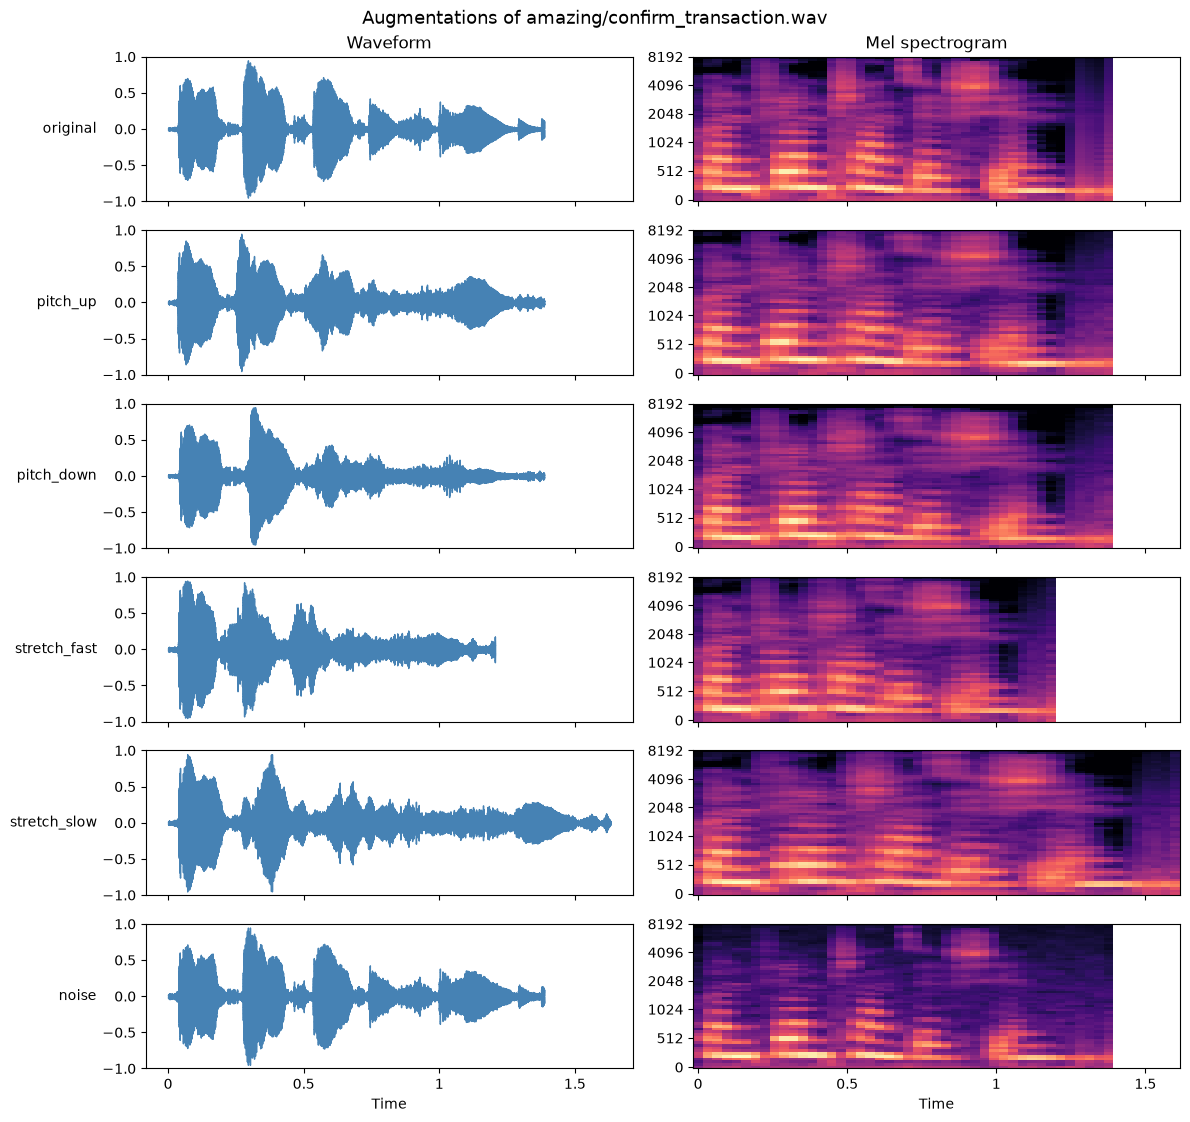

original


pitch_up


pitch_down


stretch_fast


stretch_slow


noise


In [7]:
# Show every version of one recording
example_id = examples.iloc[0]
versions = augmented[example_id]
fig, axes = plt.subplots(len(versions), 2, figsize=(12, 1.9 * len(versions)), sharex="col")
for i, (name, y) in enumerate(versions.items()):
    plot_wave(y, axes[i, 0])
    plot_mel(y, axes[i, 1])
    axes[i, 0].set_ylabel(name, rotation=0, ha="right", va="center", fontsize=10)
    axes[i, 1].set_ylabel("")
    for ax in axes[i]:
        if i < len(versions) - 1:
            ax.set_xlabel("")
axes[0, 0].set_title("Waveform")
axes[0, 1].set_title("Mel spectrogram")
fig.suptitle(f"Augmentations of {example_id}", fontsize=13)
fig.tight_layout()
fig.savefig(FIG_DIR / "audio_augmentation_example.png")
plt.show()

for name, y in versions.items():
    print(name)
    display(Audio(y, rate=SR))

## 5. Feature extraction → `audio_features.csv`

Each clip (original or augmented) becomes one row of 48 numbers, computed by
`vm.extract_features` in `scripts/voice_model.py`:

| Feature | Columns | What it captures |
|---|---|---|
| MFCC 1–20, mean and std | 40 | the shape of the vocal tract; the classic speaker-recognition feature |
| Spectral roll-off, mean and std | 2 | frequency below which 85 % of the energy lies (brightness) |
| RMS energy, mean and std | 2 | loudness and how much it varies |
| Zero-crossing rate, mean | 1 | how noisy or breathy the voice is |
| Spectral centroid, mean | 1 | the "centre of mass" of the spectrum |
| Pitch, median (Hz) and spread (semitones) | 2 | how high the voice is and how much it moves; changes little between phrases |

The CSV also stores which member, phrase, recording and augmentation each row
came from. Unauthorized clips are included with `authorized = False`; they are
never used for training.

For this run, six member recordings produce 36 feature rows and the two
unauthorized recordings produce 12 rows, for 48 rows in total. Each row has 48
numeric features plus six metadata fields. Only the 36 authorized rows are used
to fit the speaker classifiers. The unauthorized rows are used for threshold
calibration, not as a fourth enrolled speaker.


In [8]:
rows = []
meta = recordings.set_index("recording_id")
for rid, versions in augmented.items():
    for aug, y in versions.items():
        rows.append({"member": meta.loc[rid, "member"], "phrase": meta.loc[rid, "phrase"],
                     "take": meta.loc[rid, "take"], "recording_id": rid, "augmentation": aug,
                     "authorized": True, **vm.extract_features(y, SR)})
for rid, versions in augmented_unauthorized.items():
    for aug, y in versions.items():
        rows.append({"member": "unauthorized", "phrase": vm.parse_recording_name(rid)[0],
                     "take": vm.parse_recording_name(rid)[1], "recording_id": rid,
                     "augmentation": aug, "authorized": False, **vm.extract_features(y, SR)})

features = pd.DataFrame(rows)
features['split'] = features.apply(lambda row: 'member' if row['authorized'] else
    ('test' if Path(row['recording_id']).name.split('_')[0].lower() in TEST_PEOPLE else 'calibration'), axis=1)
features['person'] = features.apply(lambda row: row['member'] if row['authorized'] else Path(row['recording_id']).name.split('_')[0].lower(), axis=1)
for idx in features.index[~features['authorized']]:
    filename = features.at[idx, 'recording_id'].lower()
    features.at[idx, 'phrase'] = 'confirm_transaction' if 'confirm' in filename else 'yes_approve'
features.to_csv(FEATURES_CSV, index=False)
print(f"Saved {rel(FEATURES_CSV)}: {features.shape[0]} rows x {features.shape[1]} columns "
      f"({len(vm.FEATURE_COLUMNS)} features)")
display(features.groupby(["member", "augmentation"]).size().unstack(fill_value=0))
display(features.head())

Saved data/audio_features.csv: 72 rows x 56 columns (48 features)


augmentation,noise,original,pitch_down,pitch_up,stretch_fast,stretch_slow
member,,,,,,
amazing,2,2,2,2,2,2
gilbert,2,2,2,2,2,2
kate,2,2,2,2,2,2
unauthorized,6,6,6,6,6,6


,member,phrase,take,recording_id,augmentation,authorized,mfcc_1_mean,mfcc_2_mean,mfcc_3_mean,mfcc_4_mean,...,rolloff_mean,rolloff_std,rms_mean,rms_std,zcr_mean,centroid_mean,pitch_median_hz,pitch_std_semitones,split,person
0,amazing,confirm_transaction,1,amazing/confirm_transaction.wav,original,True,-208.340729,98.291229,13.178794,38.872658,...,2473.721591,1834.123326,0.174853,0.094218,0.116999,1374.393259,239.020867,3.974791,member,amazing
1,amazing,confirm_transaction,1,amazing/confirm_transaction.wav,pitch_up,True,-202.592636,90.937515,19.807102,27.481194,...,2754.261364,1842.577793,0.172918,0.094141,0.098855,1433.275605,266.329808,2.505265,member,amazing
2,amazing,confirm_transaction,1,amazing/confirm_transaction.wav,pitch_down,True,-221.647812,103.772881,12.520188,46.986660,...,2517.578125,1524.153136,0.141063,0.100105,0.086637,1279.991635,229.653035,1.010650,member,amazing
3,amazing,confirm_transaction,1,amazing/confirm_transaction.wav,stretch_fast,True,-179.629135,99.074760,17.783968,34.518021,...,2653.166118,1615.249144,0.176233,0.106168,0.090255,1362.656157,252.961866,1.133733,member,amazing
4,amazing,confirm_transaction,1,amazing/confirm_transaction.wav,stretch_slow,True,-196.507935,93.908714,17.199266,36.616608,...,2727.481618,1725.653642,0.154604,0.089217,0.093022,1409.296570,245.666164,1.643443,member,amazing


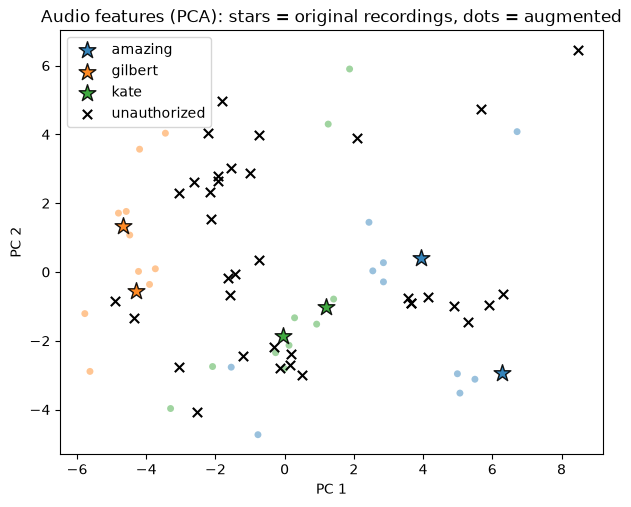

In [9]:
# Do the members form separate groups? Project the features onto 2 dimensions.
scaled = StandardScaler().fit_transform(features[vm.FEATURE_COLUMNS])
coords = PCA(n_components=2, random_state=SEED).fit_transform(scaled)

fig, ax = plt.subplots(figsize=(7, 5.5))
colors = plt.cm.tab10(np.arange(len(MEMBERS)))
for color, member in zip(colors, MEMBERS):
    for is_orig, marker, size in [(False, "o", 25), (True, "*", 160)]:
        mask = ((features["member"] == member) & (features["augmentation"].eq("original") == is_orig)).to_numpy()
        ax.scatter(coords[mask, 0], coords[mask, 1], color=color, marker=marker, s=size,
                   alpha=0.9 if is_orig else 0.45, edgecolor="k" if is_orig else "none",
                   label=member if is_orig else None)
mask = (~features["authorized"]).to_numpy()
if mask.any():
    ax.scatter(coords[mask, 0], coords[mask, 1], color="black", marker="x", s=45, label="unauthorized")
ax.set_xlabel("PC 1")
ax.set_ylabel("PC 2")
ax.set_title("Audio features (PCA): stars = original recordings, dots = augmented")
ax.legend()
fig.savefig(FIG_DIR / "audio_features_pca.png")
plt.show()

## 6. Train and evaluate the voice model

**Why not a normal train/test split?** The augmented copies of a recording are
almost identical to it. If a copy lands in training and the original in testing,
the score is inflated. So every recording and its copies stay together.

**Leave-one-recording-out:** for each recording, train on all the other
recordings (with their copies) and test on the held-out recording and its copies.
Every recording gets tested once by a model that never heard it, which uses the
small dataset fully.

**How many takes matters.** With one take per phrase, holding out someone's
"Yes, approve" leaves only their "Confirm transaction" to learn from, so the test
becomes "recognise this voice saying a phrase you never heard from them". The
app may receive a new take of a phrase the model has heard, but different
microphones and rooms can still make that difficult. More takes per phrase
would make evaluation more representative of repeated use.

Two models are compared: **Random Forest** and **Logistic Regression** (on
standardised features). The one with the higher macro F1 (then lower log loss)
is kept and retrained on all recordings.

In [10]:
members_df = features[features["authorized"]].reset_index(drop=True)
X = members_df[vm.FEATURE_COLUMNS]
y = members_df["member"].to_numpy()
groups = members_df["recording_id"].to_numpy()
X_unauth = features.loc[features["split"].eq("calibration"), vm.FEATURE_COLUMNS]
CLASSES = MEMBERS

MODELS = {
    "Random Forest": RandomForestClassifier(n_estimators=300, class_weight="balanced",
                                            random_state=SEED),
    "Logistic Regression": make_pipeline(StandardScaler(),
                                         LogisticRegression(max_iter=5000, class_weight="balanced")),
}

def full_proba(model, X_):
    """predict_proba with a column for every member, even one missing from a training fold."""
    out = np.zeros((len(X_), len(CLASSES)))
    proba = model.predict_proba(X_)
    for j, cls in enumerate(model.classes_):
        out[:, CLASSES.index(cls)] = proba[:, j]
    return out

is_original = members_df["augmentation"].eq("original").to_numpy()
results, oof = {}, {}
for name, model in MODELS.items():
    proba = np.zeros((len(X), len(CLASSES)))
    unauth_scores = []
    for train_idx, test_idx in LeaveOneGroupOut().split(X, y, groups):
        fold_model = clone(model).fit(X.iloc[train_idx], y[train_idx])
        proba[test_idx] = full_proba(fold_model, X.iloc[test_idx])
        if len(X_unauth):
            unauth_scores.append(full_proba(fold_model, X_unauth).max(axis=1))
    pred = np.array(CLASSES)[proba.argmax(axis=1)]
    results[name] = {
        "accuracy": accuracy_score(y, pred),
        "f1_macro": f1_score(y, pred, average="macro", labels=CLASSES, zero_division=0),
        "log_loss": log_loss(y, proba, labels=CLASSES),
        "accuracy_originals_only": accuracy_score(y[is_original], pred[is_original]),
    }
    oof[name] = {"proba": proba, "pred": pred,
                 "unauth_scores": np.concatenate(unauth_scores) if unauth_scores else np.array([])}

comparison = pd.DataFrame(results).T.round(3)
display(comparison)

BEST = min(results, key=lambda n: (-results[n]["f1_macro"], results[n]["log_loss"]))
print(f"Chosen model: {BEST}")

,accuracy,f1_macro,log_loss,accuracy_originals_only
Random Forest,0.944,0.943,0.573,1.000
Logistic Regression,0.778,0.745,0.503,0.833


Chosen model: Random Forest


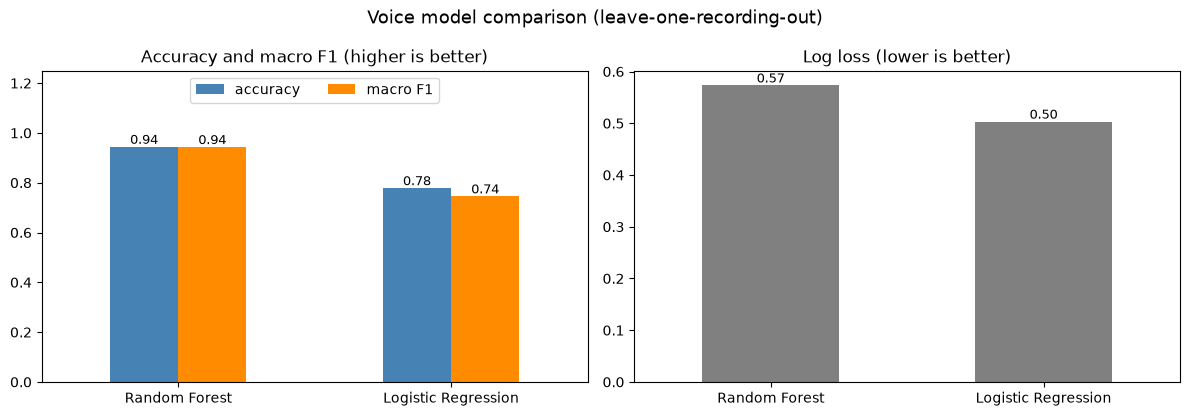

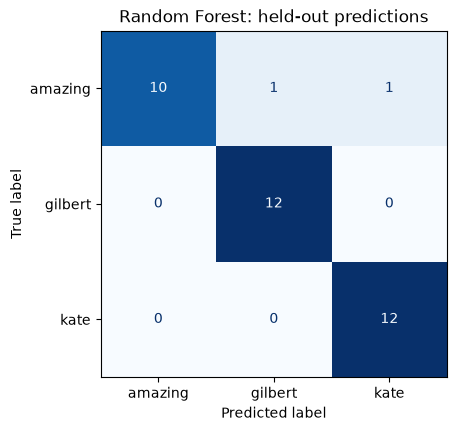

,share_correct
recording_id,
amazing/confirm_transaction.wav,0.833333
amazing/yes_approve.wav,0.833333
gilbert/confirm_transaction.wav,1.000000
gilbert/yes_approve.wav,1.000000
kate/confirm_transaction.wav,1.000000
kate/yes_approve.wav,1.000000


In [11]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
comparison[["accuracy", "f1_macro"]].plot.bar(ax=axes[0], rot=0, color=["steelblue", "darkorange"])
axes[0].set_ylim(0, 1.25)
axes[0].set_title("Accuracy and macro F1 (higher is better)")
axes[0].legend(["accuracy", "macro F1"], loc="upper center", ncol=2)
comparison["log_loss"].plot.bar(ax=axes[1], rot=0, color="gray")
axes[1].set_title("Log loss (lower is better)")
for ax in axes:
    for bar in ax.patches:
        ax.annotate(f"{bar.get_height():.2f}", (bar.get_x() + bar.get_width() / 2, bar.get_height()),
                    ha="center", va="bottom", fontsize=9)
fig.suptitle("Voice model comparison (leave-one-recording-out)", fontsize=13)
fig.tight_layout()
fig.savefig(FIG_DIR / "audio_model_comparison.png")
plt.show()

fig, ax = plt.subplots(figsize=(5.5, 4.5))
ConfusionMatrixDisplay.from_predictions(y, oof[BEST]["pred"], labels=CLASSES, ax=ax,
                                        cmap="Blues", colorbar=False)
ax.set_title(f"{BEST}: held-out predictions")
fig.savefig(FIG_DIR / "audio_confusion_matrix.png")
plt.show()

# Which recordings does the model struggle with?
per_recording = (members_df.assign(correct=oof[BEST]["pred"] == y)
                 .groupby("recording_id")["correct"].mean().rename("share_correct").to_frame())
display(per_recording.sort_values("share_correct"))

## 7. Conservative rejection calibration

The former threshold maximised genuine acceptance minus unauthorized acceptance.
That compromise selected 0.50 and admitted calibration strangers, which is unsuitable
for the desired rejection behaviour. We now choose the smallest representable threshold
**strictly above every calibration confidence** from Frank and Gabriella, across the
selected model's fold fits and its final member-only fit. This targets zero observed
calibration false accepts. It does not guarantee zero false accepts on new strangers.

Placide is excluded from model fitting, model selection and threshold selection.
However, his earlier failure prompted this revision, so his new result is a regression
test on a previously inspected person, not a pristine independent final test. A fresh
unauthorized speaker is needed after the policy is frozen.

The same stricter threshold is applied to held-out member predictions to expose the
cost in false rejections. If calibration confidence reaches 1, the policy explicitly
rejects all instead of falling back to a permissive threshold. Empty calibration is
an error. A tied top identity is always denied. Confidence is a classifier score,
not a calibrated probability that the speaker is authorized.


Threshold (strictly above calibration maximum): 0.720000
  Genuine clips accepted:      25.0%
  Unauthorized clips accepted: 0.0%


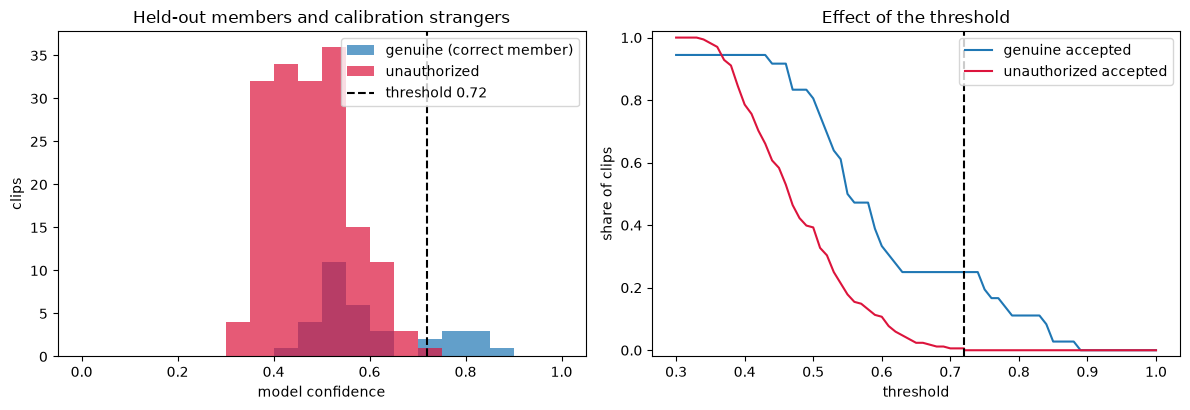

In [12]:
true_idx = np.array([CLASSES.index(c) for c in y])
genuine_scores = oof[BEST]["proba"][np.arange(len(y)), true_idx]
genuine_correct = (oof[BEST]["pred"] == y) & ((oof[BEST]["proba"] == oof[BEST]["proba"].max(axis=1, keepdims=True)).sum(axis=1) == 1)
# Fit the deployed classifier BEFORE calibrating its gate. Members only.
final_model = clone(MODELS[BEST]).fit(X, y)
assert list(final_model.classes_) == CLASSES
final_calibration_scores = full_proba(final_model, X_unauth).max(axis=1)
unauth_scores = np.r_[oof[BEST]['unauth_scores'], final_calibration_scores]
THRESHOLD = vm.calibrate_rejection_threshold(unauth_scores)

candidates = np.unique(np.r_[np.round(np.arange(0.30, 1.001, 0.01), 2), THRESHOLD])
sweep = pd.DataFrame({
    "threshold": candidates,
    "genuine_accepted": [np.mean(genuine_correct & (genuine_scores >= t)) for t in candidates],
    "unauthorized_accepted": [np.mean(unauth_scores >= t) if len(unauth_scores) else np.nan
                              for t in candidates],
})

# The policy is zero observed calibration false accepts, not balanced margin.
assert not np.any(unauth_scores >= THRESHOLD)
if THRESHOLD > 1:
    print('WARNING: calibration requires reject-all; gather new data before use.')

def pct(value):
    return "n/a" if pd.isna(value) else f"{value:.1%}"

at = sweep.loc[sweep["threshold"].eq(THRESHOLD)].iloc[0]
print(f"Threshold (strictly above calibration maximum): {THRESHOLD:.6f}")
print(f"  Genuine clips accepted:      {pct(at['genuine_accepted'])}")
print(f"  Unauthorized clips accepted: {pct(at['unauthorized_accepted'])}")

fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
bins = np.linspace(0, 1, 21)
axes[0].hist(genuine_scores[genuine_correct], bins=bins, alpha=0.7, label="genuine (correct member)")
if len(unauth_scores):
    axes[0].hist(unauth_scores, bins=bins, alpha=0.7, color="crimson", label="unauthorized")
axes[0].axvline(THRESHOLD, color="k", ls="--", label=f"threshold {THRESHOLD:.2f}")
axes[0].set_xlabel("model confidence")
axes[0].set_ylabel("clips")
axes[0].set_title("Held-out members and calibration strangers")
axes[0].legend()
axes[1].plot(sweep["threshold"], sweep["genuine_accepted"], label="genuine accepted")
if len(unauth_scores):
    axes[1].plot(sweep["threshold"], sweep["unauthorized_accepted"], color="crimson",
                 label="unauthorized accepted")
axes[1].axvline(THRESHOLD, color="k", ls="--")
axes[1].set_xlabel("threshold")
axes[1].set_ylabel("share of clips")
axes[1].set_ylim(-0.02, 1.02)
axes[1].set_title("Effect of the threshold")
axes[1].legend()
fig.tight_layout()
fig.savefig(FIG_DIR / "audio_threshold.png")
plt.show()

In [13]:
# Save the same member-fitted model used during threshold calibration.
assert list(final_model.classes_) == CLASSES

bundle = {
    "model": final_model,
    "model_name": BEST,
    "classes": CLASSES,
    "feature_columns": vm.FEATURE_COLUMNS,
    "threshold": THRESHOLD,
    "threshold_policy": "strictly_above_max_calibration_confidence",
    "calibration_max_confidence": float(unauth_scores.max()),
    "calibration_score_count": len(unauth_scores),
    "test_status": "previously_inspected_regression_person_not_fresh_test",
    "sample_rate": SR,
    "calibration_people": sorted(CALIBRATION_PEOPLE),
    "test_people": sorted(TEST_PEOPLE),
    "metrics": {k: round(float(v), 4) for k, v in results[BEST].items()},
    "n_recordings": int(len(recordings)),
    "augmentations": list(AUGMENTATIONS),
}
joblib.dump(bundle, MODEL_PATH)
vm._MODEL_CACHE.clear()  # make verify_voice() load the new file
print(f"Saved {rel(MODEL_PATH)} ({BEST}, threshold {THRESHOLD:.2f})")

Saved models/voice_model.pkl (Random Forest, threshold 0.72)


## 8. Verify all original recordings

Each of the six original member recordings is checked against all three claims,
followed by each of the six unauthorized recordings against all claims: 36 checks.
These are regression and interface checks. Member originals were used for final fitting;
Frank and Gabriella were used for calibration; Placide was previously inspected.
Use the grouped member acceptance rate for the false-rejection trade-off, and collect
new independent recordings before claiming generalization.


In [14]:
checks = []
first_takes = recordings.sort_values("take").drop_duplicates("member").set_index("member")["path"]
for recording in recordings.itertuples():
    member, path = recording.member, recording.path
    for claim in CLASSES:
        approved, confidence = vm.verify_voice(path, claim, MODEL_PATH)
        checks.append({"clip": rel(path), "claimed": claim,
                       "expected": "approve" if claim == member else "deny",
                       "result": "approve" if approved else "deny",
                       "confidence": round(confidence, 3)})
for path in unauthorized["path"] if not unauthorized.empty else []:
    for claim in CLASSES:
        approved, confidence = vm.verify_voice(path, claim, MODEL_PATH)
        checks.append({"clip": rel(path), "claimed": claim, "expected": "deny",
                       "result": "approve" if approved else "deny",
                       "confidence": round(confidence, 3)})

checks = pd.DataFrame(checks)
checks["correct"] = checks["expected"] == checks["result"]
display(checks)
print(f"{checks['correct'].sum()}/{len(checks)} checks behaved as expected")

,clip,claimed,expected,result,confidence,correct
0,data/audio/amazing/confirm_transaction.wav,amazing,approve,approve,0.983,True
1,data/audio/amazing/confirm_transaction.wav,gilbert,deny,deny,0.000,True
2,data/audio/amazing/confirm_transaction.wav,kate,deny,deny,0.017,True
3,data/audio/amazing/yes_approve.wav,amazing,approve,approve,0.967,True
4,data/audio/amazing/yes_approve.wav,gilbert,deny,deny,0.003,True
5,data/audio/amazing/yes_approve.wav,kate,deny,deny,0.030,True
6,data/audio/gilbert/confirm_transaction.wav,amazing,deny,deny,0.000,True
7,data/audio/gilbert/confirm_transaction.wav,gilbert,approve,approve,0.990,True
8,data/audio/gilbert/confirm_transaction.wav,kate,deny,deny,0.010,True
9,data/audio/gilbert/yes_approve.wav,amazing,deny,deny,0.020,True


36/36 checks behaved as expected


In [15]:
# The same check from a terminal, as the app or a teammate would run it
demo_member = CLASSES[0]
demo_clip = first_takes[demo_member]
command = [sys.executable, str(ROOT / "scripts" / "voice_model.py"), rel(demo_clip), demo_member]
print("$ python scripts/voice_model.py", rel(demo_clip), demo_member)
result = subprocess.run(command, cwd=ROOT, capture_output=True, text=True)
print(result.stdout or result.stderr)

$ python scripts/voice_model.py data/audio/amazing/confirm_transaction.wav amazing


APPROVED: voice matches 'amazing' (confidence 0.98, threshold 0.72)
Closest enrolled voice: amazing (0.98)



## 9. Results discussion and report summary

This run contains six member originals (two phrases from each of Amazing, Gilbert and
Kate) and six unauthorized originals (two each from Frank, Gabriella and Placide).
Five augmentations per recording produce 72 feature rows: 36 member rows, 24 unauthorized
calibration rows and 12 unauthorized test rows. Each row has 48 numeric features plus
metadata. Scaling and model fitting happen within each member recording-group fold.

The model comparison below reports accuracy, macro F1 and log loss. Selection prioritises
macro F1 and then log loss; the lowest-loss model need not be the one selected. These
same validation folds select the model, so there is no separate final member test set.
Speaker-classification accuracy is distinct from transaction acceptance after thresholding.

Functional checks use the final refitted model on supplied original clips: member examples
were used for fitting and Frank/Gabriella for calibration. Placide is excluded from fitting and calibration but was previously inspected; his original and augmented rejection rates are reported separately below.
Do not present all functional checks as an independent accuracy estimate.

Recording quality flags are shown in Section 1. A quiet recording or differing background
conditions can influence the result even after normalization. Extra independent takes,
clearer unauthorized recordings and more withheld speakers are needed. Augmentation does
not create independent sessions; the system has no anti-replay or synthetic-speech test.

The face component can pass a recognized lowercase member name to
`verify_voice(audio_path, expected_name)`. The future app must display a recommendation
only if verification approves. This notebook covers the audio component, not the complete
transaction demonstration.


The original 0.50 balanced-margin threshold is superseded by the conservative
calibration rule in Section 7. Both the successful rejections and any reduction in
held-out genuine acceptance must be reported. Classification accuracy does not
change when only the acceptance policy changes.


In [16]:
per_member = recordings.groupby("member").size()
figures = sorted(p.name for p in FIG_DIR.glob("audio_*.png"))
lines = [
    "VOICE MODEL SUMMARY",
    "===================",
    f"Members enrolled:        {len(CLASSES)} ({', '.join(CLASSES)})",
    f"Recordings:              {len(recordings)} "
    f"({', '.join(f'{m}: {n}' for m, n in per_member.items())})",
    f"Unauthorized clips:      {len(unauthorized)}",
    f"Augmentations:           {len(AUGMENTATIONS)} per recording ({', '.join(AUGMENTATIONS)})",
    f"Feature rows:            {len(features)} ({len(members_df)} member, "
    f"{len(features) - len(members_df)} unauthorized), {len(vm.FEATURE_COLUMNS)} features each",
    "Evaluation:              leave-one-recording-out (copies stay with their recording)",
    "",
    comparison.to_string(),
    "",
    f"Chosen model:            {BEST}",
    f"Approval threshold:      {THRESHOLD:.2f}",
    f"  genuine accepted:      {pct(at['genuine_accepted'])}",
    f"  unauthorized accepted: {pct(at['unauthorized_accepted'])}",
    f"verify_voice checks:     {checks['correct'].sum()}/{len(checks)} as expected",
    "",
    "Figures in report/figures/: " + ", ".join(figures),
]
print("\n".join(lines))
# Evaluate the untouched unauthorized person after final fitting and threshold selection.
import json
test_features = features[features['split'].eq('test')]
test_scores = full_proba(final_model, test_features[vm.FEATURE_COLUMNS]).max(axis=1)
test_original = test_features['augmentation'].eq('original').to_numpy()
test_false_acceptance = float(np.mean(test_scores[test_original] >= THRESHOLD))
test_all_false_acceptance = float(np.mean(test_scores >= THRESHOLD))
summary = {'model': BEST, 'metrics': results, 'threshold': THRESHOLD,
           'threshold_policy': bundle['threshold_policy'],
           'calibration_max_confidence': bundle['calibration_max_confidence'],
           'test_status': bundle['test_status'],
           'calibration_people': sorted(CALIBRATION_PEOPLE), 'test_people': sorted(TEST_PEOPLE),
           'genuine_oof_acceptance': float(at['genuine_accepted']),
           'calibration_false_acceptance': float(at['unauthorized_accepted']),
           'test_original_false_acceptance': test_false_acceptance,
           'test_augmented_false_acceptance': test_all_false_acceptance,
           'test_originals': int(test_original.sum()),
           'functional_checks_passed': int(checks.correct.sum()), 'functional_checks_total': len(checks)}
(ROOT/'report/audio_results.json').write_text(json.dumps(summary, indent=2), encoding='utf-8')
print('Calibration people:', sorted(CALIBRATION_PEOPLE), '| Withheld test person:', sorted(TEST_PEOPLE))
print('Placide original-clip false acceptance:', pct(test_false_acceptance))
print('Placide all-variant false acceptance:', pct(test_all_false_acceptance))
checks.to_csv(ROOT/'report/audio_verification_checks.csv', index=False)

member_check_mask = checks['clip'].str.startswith('data/audio/') & checks['expected'].eq('approve')
unauth_check_mask = checks['clip'].str.startswith('data/unauthorized/')
summary['member_original_acceptance'] = float(checks.loc[member_check_mask, 'correct'].mean())
summary['unauthorized_original_claims_rejected'] = int(checks.loc[unauth_check_mask, 'correct'].sum())
summary['unauthorized_original_claims_total'] = int(unauth_check_mask.sum())
summary['genuine_oof_false_rejection'] = 1 - summary['genuine_oof_acceptance']
(ROOT/'report/audio_results.json').write_text(json.dumps(summary, indent=2), encoding='utf-8')
print('Current rejection policy:', summary['threshold_policy'])
print('Genuine held-out false rejection:', pct(summary['genuine_oof_false_rejection']))
print('Original member acceptance (training samples):', pct(summary['member_original_acceptance']))
print('Placide is a previously inspected regression person; obtain fresh final test recordings.')


VOICE MODEL SUMMARY
Members enrolled:        3 (amazing, gilbert, kate)
Recordings:              6 (amazing: 2, gilbert: 2, kate: 2)
Unauthorized clips:      6
Augmentations:           5 per recording (pitch_up, pitch_down, stretch_fast, stretch_slow, noise)
Feature rows:            72 (36 member, 36 unauthorized), 48 features each
Evaluation:              leave-one-recording-out (copies stay with their recording)

                     accuracy  f1_macro  log_loss  accuracy_originals_only
Random Forest           0.944     0.943     0.573                    1.000
Logistic Regression     0.778     0.745     0.503                    0.833

Chosen model:            Random Forest
Approval threshold:      0.72
  genuine accepted:      25.0%
  unauthorized accepted: 0.0%
verify_voice checks:     36/36 as expected

Figures in report/figures/: audio_augmentation_example.png, audio_confusion_matrix.png, audio_features_pca.png, audio_model_comparison.png, audio_spectrograms.png, audio_threshold.p